# 10 - The Dynamic Workflow Engine: a Glass Box

**Part B - Petrophys Curriculum**

The dynamic workflow is the headline capability of `petrophys`: hand it a raw
well and it *inspects what curves are present*, decides which petrophysical
modules can run, chooses a method for each one, and executes the whole
interpretation pipeline in the correct order:

> QC -> Volume of clay -> Porosity -> Lithology -> Rw -> Water saturation ->
> Permeability -> Rock quality -> Net pay

The important word is **dynamic**. Nothing is hard-coded to a fixed curve list.
If a well has no resistivity, the saturation step is skipped rather than
crashing. Rw requires a supported input or calculation route; the workflow does
not silently introduce a default Rw;
if only a density log is present, porosity falls back to a density-only route.

This lesson treats the engine as a **glass box**. We do not just read the
final answer - we read the *step trace*: which steps executed, which were
skipped, the method chosen per step and *why*, and the exact parameters used.
Then we prove it is steerable by overriding the saturation model and cutoffs
and measuring the difference in net pay.

## Learning goals

- Run `petrophys.interpret` on a real well and read `DynamicWorkflowResult`.
- Understand how the engine **auto-detects** available input curves and selects
  a method per module.
- Inspect the **step trace**: executed vs skipped steps, method, inputs,
  outputs, parameters, and human-readable decisions.
- Plot resulting curves (VCL, PHIE, SW) against the raw logs.
- Demonstrate **parameter overrides** - change the Sw model and the pay
  cutoff one knob at a time and decompose their effects on net pay.
- Understand copy-by-default behavior and explicit lithology source selection.
- Run a **zoned-by-formation** interpretation and summarise pay per formation.

### Prerequisites

Familiarity with the individual modules (clay volume, porosity, saturation,
net pay) from Part A helps, but this lesson is self-contained.

## Why this matters

A manual petrophysical interpretation is a long chain of decisions: *which*
clay indicator, *which* porosity route given the logs you have, *which*
saturation equation for this shaliness, *what* cutoffs for net pay. Each choice
depends on the previous one and on the curves actually available in the file.

The dynamic workflow encodes that decision chain once and makes it auditable.
The step trace is what turns an opaque "the model says 42 m of pay" into a
defensible interpretation you can hand to a reviewer.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.preprocessing.standardization import standardize_curves
from petrophys.workflow import (
    run_dynamic_workflow,
    DynamicWorkflowConfig,
    DynamicWorkflowResult,
    run_dynamic_workflow_with_zones,
)
from petrophys.datasets import DATA_DIR

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("petrophys", petrophys.__version__)
print("DynamicWorkflowConfig ->", DynamicWorkflowConfig.__name__)
print("DynamicWorkflowResult ->", DynamicWorkflowResult.__name__)

petrophys 3.0.0
DynamicWorkflowConfig -> DynamicWorkflowConfig
DynamicWorkflowResult -> DynamicWorkflowResult


## 1. Read and plot before interpretation

We use 30/6-5, a North Sea clastic well with embedded vendor lithology. No external formation or lithology file is required. `petrophys.read` only loads data; `petrophys.plot` displays existing curves.

The interpretation workflow standardizes inputs by default. Unlike the lower-level mutating API, `petrophys.interpret` works on a copy. Keep the raw well available when comparing configurations.

Well: 30/6-5
Depth: 176.60999 3556.08032 m
Curves: LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


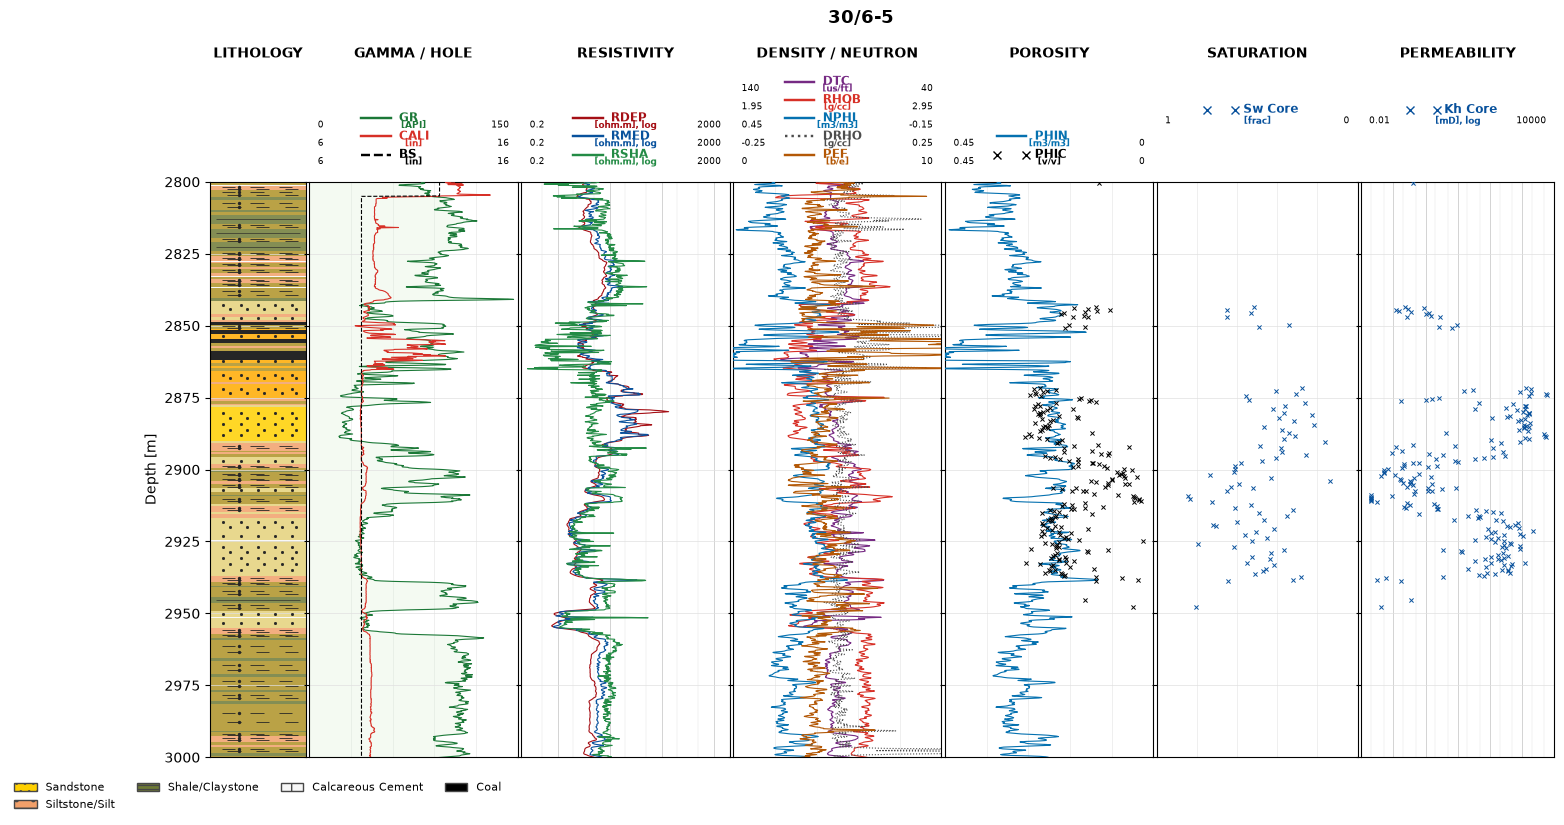

In [2]:
def load_well():
    """Return a fresh, unprocessed LAS well."""
    return petrophys.read(petrophys.sample("30_6-5"))

raw = load_well()
well = raw
print("Well:", raw.name)
print("Depth:", raw.top, raw.bottom, raw.depth_unit)
print("Curves:", ", ".join(raw.curves))
raw_viewer = petrophys.plot(raw, depth_range=(2800, 3000), figsize=(14, 8))
raw_viewer.show()
raw_viewer.close()

### What can the engine detect?

The engine gates each module on the curves it can find. Below we probe an
adapted list of the curve families that drive those `_can_*` gates, so you can
see, *before* running anything, which raw inputs are present.

In [3]:
# Curve families that drive the engine's _can_* gates (adapted list)
probe = ["GR", "SP", "NPHI", "RHOB", "DTC", "DTS", "RDEP", "RT",
         "RSHA", "RXO", "PEF", "CALI", "BS", "DRHO",
         "PHIC", "KH_CORE", "SWC", "SOC"]
present = [name for name in probe if well.has_curve(name)]
missing = [name for name in probe if not well.has_curve(name)]
print("Detected inputs :", ", ".join(present))
print("Not present     :", ", ".join(missing))


Detected inputs : GR, SP, NPHI, RHOB, DTC, RDEP, RSHA, PEF, CALI, BS, DRHO, PHIC, KH_CORE, SWC, SOC
Not present     : DTS, RT, RXO


#### What the detected inputs enable

- **GR** enables clay-volume estimation.
- **RHOB, NPHI, and PEF** support porosity and multi-mineral lithology.
- **RDEP** supports formation-water, saturation, and invasion calculations.
- **PHIC and KH_CORE** enable log-to-core calibration.

The workflow evaluates these prerequisites explicitly before selecting each
step.


## 2. Configure the run

`DynamicWorkflowConfig` is a dataclass of *optional* parameters. Anything left
`None` is auto-detected or defaulted - including the net-pay cutoffs, which
resolve to the curriculum standards (`STANDARD_CUTOFFS`) for the well's
lithology.

The 30/6-5 LAS header carries the operator's parameter block (BHT, Rw, Rmf,
mud-filtrate chlorides), so the environment comes from the file rather than
from guesses. One value needs care rather than trust: the header prints
**RW = 0.70 ohm.m with no temperature basis**; lesson 09 back-calculates the
value the operator's evaluation actually used - **0.070 ohm.m at reservoir
temperature (~230 F)** - and case study 1 cross-checks it against the NPD fact
page. We apply the reconciled value and record the decision here and in the
trace.

In [4]:
_hdr = load_well()   # peek at the LAS ~Params block
BHT_F = float(_hdr.get_parameter("BHT")) * 9.0 / 5.0 + 32.0   # 126 degC
SALINITY_PPM = float(_hdr.get_parameter("CLFL")) * 1.645      # Cl -> NaCl eq.

ENV = DynamicWorkflowConfig(
    # --- environment from the LAS header (one documented reconciliation) ---
    bht_f=round(BHT_F, 1),         # header BHT (126 degC = 258.8 degF)
    td_ft=11700.0,                 # ~3566 m total depth in feet
    rw=0.070,                      # header prints 0.70; reconciled (lesson 09)
    rw_meas_temp_f=230.0,          # Rw basis: reservoir temperature
    salinity_ppm=round(SALINITY_PPM),
    rmf_at_meas_temp=float(_hdr.get_parameter("RMF")),   # 0.08 ohm.m
    # --- interpretation choices ---
    lithology="clastic",
    matrix_type="sandstone",
    sw_model="auto",        # let the router pick per-depth
    # cutoffs left unset -> clastic curriculum standards resolve automatically
)
print("Environment (header-derived; flag the RW reconciliation in any report):")
for k in ["bht_f", "td_ft", "rw", "salinity_ppm", "rmf_at_meas_temp"]:
    print("  %-16s = %s" % (k, getattr(ENV, k)))
from petrophys.evaluation import standard_cutoffs
std = standard_cutoffs(ENV.lithology)
print("Cutoffs (standard): vcl<=%.2f  sw<=%.2f  phie>=%.2f"
      % (std["vcl_cutoff"], std["sw_cutoff"], std["phie_cutoff"]))

Environment (header-derived; flag the RW reconciliation in any report):
  bht_f            = 258.8
  td_ft            = 11700.0
  rw               = 0.07
  salinity_ppm     = 33502
  rmf_at_meas_temp = 0.08
Cutoffs (standard): vcl<=0.40  sw<=0.60  phie>=0.08


## 3. Run the pipeline with explicit assumptions

`petrophys.interpret(raw, config=ENV)` returns a DynamicWorkflowResult and leaves `raw` unchanged. Use `result.well` for calculated curves. The lower-level `run_dynamic_workflow` and zoned helpers retain their in-place contracts.

The detailed configuration below is preserved for the scientific comparison. Its Rw reconciliation is a teaching-study choice; it must not be transplanted to an unrelated well.

In [5]:
before = tuple(raw.curves)
result = petrophys.interpret(raw, config=ENV)
result.raise_for_errors()
well = result.well
assert well is not raw
assert tuple(raw.curves) == before
print("Status:", result.status)
print("Executed:", ", ".join(step.step for step in result.steps_executed))
print("Skipped:", result.specific_steps_skipped)
print("Warnings:", result.warnings)

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:331: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:331: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


Status: interpreted
Executed: normalization, input_context, temperature, bad_hole, vclay, rcl, rmf, porosity, lithology, core_correction, rw, invasion, saturation, permeability, rock_quality, bvw, mhi, net_pay, permeability_benchmark_finalize, rock_quality_benchmark_finalize
Skipped: {'spectral_gamma': 'Required usable curves or parameters are unavailable', 'elemental_spectroscopy': 'Required usable curves or parameters are unavailable', 'hc_correction': 'Required usable curves or parameters are unavailable', 'porosity_refinement': 'Required usable curves or parameters are unavailable'}
Warnings: []


### Why were those steps skipped?

Inspect `steps_skipped` and `specific_steps_skipped` on the current result. A gate may be unmet, or a step may have been disabled explicitly. Missing inputs are not the same as a calculation error.

`result.success` means execution did not report a failure, not that every desired product exists. `result.status` distinguishes a usable interpretation from a no-interpretation run. `raise_for_errors` checks returned failures; `raise_on_error=True` re-raises execution exceptions during a run.

In [6]:
if result.specific_steps_skipped:
    for step, reason in result.specific_steps_skipped.items():
        print("%-22s -> %s" % (step, reason))
else:
    print("No step raised a specific skip reason.")
print()
# Computed scalars/curves the workflow surfaced on the result object
def _rng(v):
    a = np.asarray(v, dtype=float); a = a[np.isfinite(a)]
    if a.size == 0: return "n/a"
    if a.size == 1: return "%.4f" % a[0]
    return "%.4f - %.4f" % (a.min(), a.max())
print("Rw computed  :", _rng(result.rw_computed), "ohm.m")
print("Rmf computed :", _rng(result.rmf_computed), "ohm.m")

spectral_gamma         -> Required usable curves or parameters are unavailable
elemental_spectroscopy -> Required usable curves or parameters are unavailable
hc_correction          -> Required usable curves or parameters are unavailable
porosity_refinement    -> Required usable curves or parameters are unavailable

Rw computed  : 0.0625 - 0.1968 ohm.m
Rmf computed : 0.0247 - 0.0777 ohm.m


### Which lithology source did this run select?

The `input_context` trace records source selection and availability. Auto prefers attached external intervals, then a recognized vendor log, otherwise computed lithology. Alternatives are `external`, `vendor`, `computed`, or explicit `config` matrix/lithology.

To use an external file in both plotting and interpretation, attach it with `petrophys.read(..., lithology=...)` or pass `lithology_intervals` to the workflow. Missing requested inputs fail. No external file is needed for the solver route; lesson 05 demonstrates it with measured logs only.

Vendor codebooks are not universal. This example uses the recognized GeoLink curve, not arbitrary integer labels.

In [7]:
context_step = next(step for step in result.steps_executed if step.step == "input_context")
print(context_step.parameters)
print("Raw source still has", len(raw.curves), "curves")

{'requested_source': 'auto', 'selected_source': 'vendor', 'external_available': False, 'vendor_available': True}
Raw source still has 20 curves


## 4. The glass box: the step trace table

This is the heart of the lesson. `result.to_dataframe()` renders one row per
executed step with the **method chosen**, the **input curves consumed**, the
**output curves written**, and the **decisions** taken. Read it top to bottom -
it is the audit trail of the interpretation.

In [8]:
trace = result.to_dataframe()
# Compact view: what ran and how.
with pd.option_context("display.max_colwidth", 46):
    print(trace[["Step", "Status", "Method", "Input Curves", "Output Curves"]].to_string(index=False))

                           Step Status                                      Method                                                                                                                   Input Curves                                                                                                                  Output Curves
                  normalization     OK        curve_alias_and_unit_standardization BS, CALI, DRHO, DTC, DTE, GDEN, GR, KH_CORE, KV_CORE, LITHOLOGY_GEOLINK, NPHI, PEF, PHIC, RDEP, RHOB, RMED, RSHA, SOC, SP, SWC BS, CALI, DRHO, DTC, DTE, GDEN, GR, KH_CORE, KV_CORE, LITHOLOGY_GEOLINK, NPHI, PEF, PHIC, RDEP, RHOB, RMED, RSHA, SOC, SP, SWC
                  input_context     OK                 validated_geology_selection                                                                                                                                                                                                                                                    

### Zooming in on a single step's reasoning

Each `StepResult` also carries free-text `decisions` - the branch logic the
module took. Let's inspect the **saturation** step, which is where the method
routing is most interesting.

In [9]:
sat = next(s for s in result.steps_executed if s.step == "saturation")
print("Step       :", sat.step)
print("Method     :", sat.method)
print("Inputs     :", ", ".join(sat.input_curves))
print("Outputs    :", ", ".join(sat.output_curves))
print("Parameters :")
for k, v in sat.parameters.items():
    print("   %-18s %s" % (k, ("%.4g" % v) if isinstance(v, float) else v))
print("Decisions  :")
for d in sat.decisions:
    print("   -> " + d)

Step       : saturation
Method     : archie+simandoux+dual_water
Inputs     : RDEP, PHIE_CC, VCL
Outputs    : SW, SXO
Parameters :
   sw_model           archie+simandoux+dual_water
   sw_model_requested auto
   sw_model_sample_counts {'archie': 19397, 'simandoux': 2602, 'dual_water': 177}
   a                  lithology_dependent
   m                  2
   n                  2
   archie_coefficients {'SANDSTONE': {'a': np.float64(0.81), 'm': np.float64(2.0), 'n': np.float64(2.0), 'closest_lithology': 'granular_sandstone', 'samples': 12904}, 'SILT': {'a': np.float64(1.0), 'm': np.float64(2.0), 'n': np.float64(2.0), 'closest_lithology': 'fine_clastic', 'samples': 6006}, 'IGNEOUS': {'a': np.float64(1.0), 'm': np.float64(2.0), 'n': np.float64(2.0), 'closest_lithology': 'non_archie_special_lithology', 'samples': 264}, 'LIMESTONE': {'a': np.float64(1.0), 'm': np.float64(2.0), 'n': np.float64(2.0), 'closest_lithology': 'clean_carbonate', 'samples': 1783}, 'SHALE': {'a': np.float64(1.0), 'm': 

The method string `archie+simandoux+dual_water` tells you the router did not
pick one global equation - it chose **per depth** based on shaliness and
lithology: clean rock (VCL below the routing cutoff) gets Archie; shaly
clastics get Simandoux because our assumed salinity (30 kppm) is at or above
the router's 20 kppm threshold (below it, Indonesia would be chosen); and
Dual-Water is the *carbonate-lithology* branch, applied where the vendor
lithology flags limestone. That per-depth routing is exactly what a manual
interpreter does by hand.

## 5. Plot the resulting curves

A glass box should let you *see* the outputs, not just tabulate them. Below we
overlay the raw triple-combo inputs with two headline computed curves - volume
of clay (`VCL`) and effective porosity (`PHIE`) - plus the net-pay flag.
We restrict to the Brent/Statfjord reservoir section for clarity.

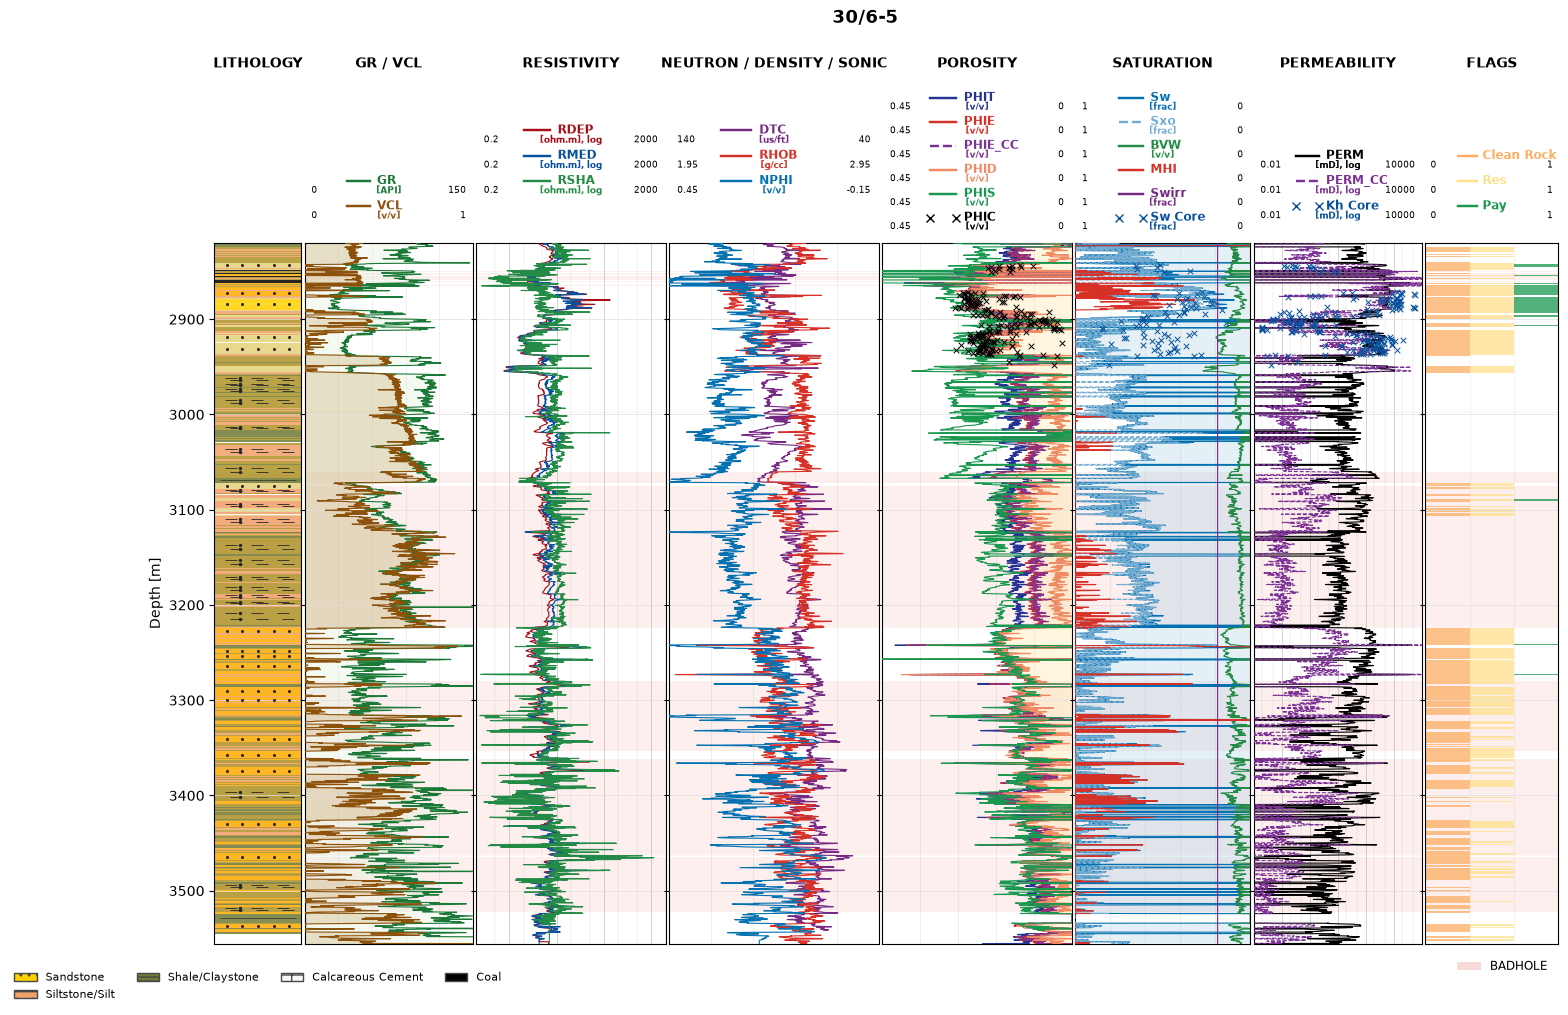

Omitted tracks: []


In [10]:
top, bot = 2820.0, min(3560.0, well.bottom)
viewer = result.plot(
    template_defaults="petrophysics",
    depth_range=(top, bot),
    figsize=(14, 10),
)
viewer.show()
viewer.close()
print("Omitted tracks:", viewer.diagnostics["omitted_tracks"])

The clay volume climbs in the shales (high GR), effective porosity opens up in
the clean sands, and the net-pay flag lights up only where porosity is high,
clay is low, water saturation is below cutoff, *and* the sample is not flagged
as bad hole - the intersection of the three cutoffs we configured plus the
bad-hole exclusion.

## 6. Parameter overrides: change one choice at a time

A -> B changes the saturation model at a fixed cutoff; B -> C tightens the cutoff at a fixed model. All three runs can start from the same raw well because `petrophys.interpret` copies it. Always inspect each result's errors and trace before comparing net pay.

In [11]:
def total_net_pay(w):
    """Net-pay thickness = flagged samples x median depth step."""
    c = w.get("NET_PAY")
    if c is None:
        return 0.0
    step = float(np.nanmedian(np.abs(np.diff(w.depth))))
    return float(np.nansum(c.data > 0.5) * step)

# Same header-derived environment as Section 2; vcl/phie cutoffs are the
# clastic standards, sw_cutoff is the experiment knob below.
BASE = dict(bht_f=258.8, td_ft=11700, rw=0.070, rw_meas_temp_f=230,
            salinity_ppm=33502, rmf_at_meas_temp=0.08, lithology="clastic",
            matrix_type="sandstone", vcl_cutoff=0.4, phie_cutoff=0.08)

# Run A: Simandoux, sw_cutoff = 0.6 (our base assumptions)
rA = petrophys.interpret(raw, config=DynamicWorkflowConfig(
    sw_model="simandoux", sw_cutoff=0.6, **BASE))

# Run B: Archie, SAME cutoff 0.6 -> isolates the model effect
rB = petrophys.interpret(raw, config=DynamicWorkflowConfig(
    sw_model="archie", sw_cutoff=0.6, **BASE))

# Run C: Archie, tighter cutoff 0.5 -> isolates the cutoff effect
rC = petrophys.interpret(raw, config=DynamicWorkflowConfig(
    sw_model="archie", sw_cutoff=0.5, **BASE))

for run in (rA, rB, rC):
    run.raise_for_errors()
wA, wB, wC = rA.well, rB.well, rC.well

pA, pB, pC = total_net_pay(wA), total_net_pay(wB), total_net_pay(wC)
print("Run A: simandoux, cutoff 0.60 -> net pay = %6.1f m" % pA)
print("Run B: archie,    cutoff 0.60 -> net pay = %6.1f m" % pB)
print("Run C: archie,    cutoff 0.50 -> net pay = %6.1f m" % pC)
print()
print("Decomposition of the total delta (%.1f m):" % (pA - pC))
print("  model effect  (A - B, same cutoff) : %6.1f m" % (pA - pB))
print("  cutoff effect (B - C, same model)  : %6.1f m" % (pB - pC))

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:331: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:331: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


Run A: simandoux, cutoff 0.60 -> net pay =  766.2 m
Run B: archie,    cutoff 0.60 -> net pay =  675.1 m
Run C: archie,    cutoff 0.50 -> net pay =  116.4 m

Decomposition of the total delta (649.8 m):
  model effect  (A - B, same cutoff) :   91.1 m
  cutoff effect (B - C, same model)  :  558.7 m


### Read the current output, not a cached benchmark

The printed decomposition separates the model effect (A - B) from the cutoff effect (B - C). Results depend on the actual workflow version, data, source selection and parameters, so fixed historical numbers are not a pass/fail criterion.

Forcing `sw_model` replaces automatic per-depth model routing. It is appropriate here as a controlled sensitivity experiment, not as proof that one model is universally right. Run C shares B's Archie saturation but uses a different pay cutoff. Compare the two curves below.

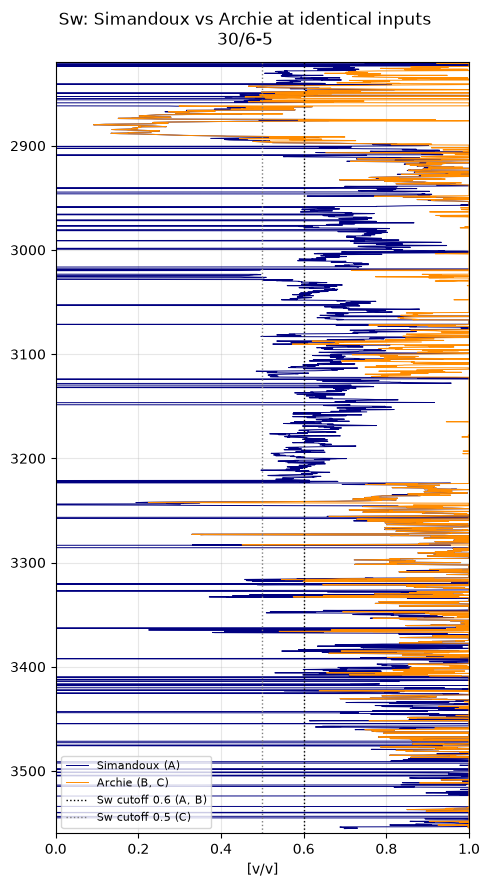

In [12]:
from petrophys.visualization import LogPlot

# LogPlot binds a single well, so attach both SW arrays onto wA as distinctly
# named curves (fresh loads of the same well give identical depth grids).
# Run C reuses the Archie Sw from run B - only its pay cutoff differs - so
# two curves and two cutoff lines tell the whole three-run story.
wA.add_curve("SW_SIMANDOUX", wA.get("SW").data, unit="v/v",
             description="Sw from run A (Simandoux)")
wA.add_curve("SW_ARCHIE", wB.get("SW").data, unit="v/v",
             description="Sw from runs B and C (Archie)")

lp = LogPlot(wA, figsize=(5, 9))
lp.create_figure(n_tracks=1)
lp.add_curve(0, "SW_SIMANDOUX", color="navy", linewidth=0.7,
             label="Simandoux (A)", xlim=(0, 1))
lp.add_curve(0, "SW_ARCHIE", color="darkorange", linewidth=0.7,
             label="Archie (B, C)")
lp.set_depth_range(top=2820, bottom=3560)

ax = lp.axes[0]
ax.axvline(0.6, color="black", ls=":", lw=1, label="Sw cutoff 0.6 (A, B)")
ax.axvline(0.5, color="grey",  ls=":", lw=1, label="Sw cutoff 0.5 (C)")
ax.legend(loc="lower left", fontsize=8)

lp.add_title("Sw: Simandoux vs Archie at identical inputs")
lp.show()

## 7. Zoned-by-formation interpretation

Real wells rarely use one set of parameters top to bottom. The `petrophys`
formation tops for 30/6-5 live in `formations_30_6-5.csv`. The engine exposes
`run_dynamic_workflow_with_zones`, which reads *zoned* parameters
(`RW_Z1`, `RW_Z2`, ...) from the LAS header and applies per-interval overrides
automatically.

30/6-5's LAS carries **no** zoned parameters, so the helper finds zero
explicit zones. It does read the **global** header block (RW, RMF, BHT) - but
header values only fill config fields you left unset: an explicitly configured
value always wins, and the run's warnings say so. That precedence matters here,
because the header prints the unreconciled `RW = 0.70` while our config
carries the documented 0.070-at-reservoir-temperature decision. Let's confirm
all of that, then do the practical thing: run once, and *summarise per
formation* using the tops CSV.

In [13]:
wz = load_well()
zres = run_dynamic_workflow_with_zones(wz, DynamicWorkflowConfig(
    bht_f=258.8, td_ft=11700, rw=0.070, rw_meas_temp_f=230, salinity_ppm=33502,
    rmf_at_meas_temp=0.08, lithology="clastic", matrix_type="sandstone",
    vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08))
print("Zoned helper ran. Base success:", zres.base_result.success)
print("Explicit LAS-defined zones found:", len(zres.zones))
print("(30/6-5 has no RW_Zn / M_Zn header parameters, so per-zone overrides = none.)")
print("Global header parameters found:", sorted(zres.global_overrides) or "none")
print("Warnings (note the header-vs-config precedence):")
for w_note in (zres.warnings or ["none"]):
    print("  -", w_note)

Zoned helper ran. Base success: True
Explicit LAS-defined zones found: 0
(30/6-5 has no RW_Zn / M_Zn header parameters, so per-zone overrides = none.)
Global header parameters found: ['bht_f', 'rmf_at_meas_temp', 'rmf_salinity_ppm', 'rw']
Warnings (note the header-vs-config precedence):
  - Header parameter maps to rw=0.7 but the config sets it explicitly; config value kept.
  - Header parameter maps to rmf_at_meas_temp=0.08 but the config sets it explicitly; config value kept.
  - Header parameter maps to bht_f=258.8 but the config sets it explicitly; config value kept.


### Summarising the single interpretation per formation

`FormationTops` + `IntervalAnalyzer` compute per-formation net pay / NTG /
averages from the curves the workflow just wrote. This is the "zoned view" that
matters for reporting. (Lesson 11 covers formation analysis in depth; here it
closes the loop on the dynamic workflow.)

In [14]:
from petrophys.evaluation.intervals import FormationTops, IntervalAnalyzer

tops = FormationTops.from_csv(str(DATA_DIR / "formations_30_6-5.csv"))
print("Loaded %d formation intervals (overlaps present: %s -" % (len(tops), tops.has_overlaps()),
      "groups + sub-formations, expected).")

analyzer = IntervalAnalyzer(wz)                        # wz has computed curves
summaries = analyzer.analyze_all(tops.clip_to_well(wz))
fdf = IntervalAnalyzer.to_dataframe(summaries)

view = fdf[["Name", "Top", "Bottom", "Gross", "Net Pay", "NTG", "Avg PHIE", "Avg Sw"]].copy()
view = view[view["Net Pay"] > 0.1].round({"Top":0,"Bottom":0,"Gross":1,"Net Pay":1,
                                          "NTG":3,"Avg PHIE":3,"Avg Sw":3})
print("\nFormations carrying net pay:")
print(view.to_string(index=False))

Loaded 20 formation intervals (overlaps present: True - groups + sub-formations, expected).

Formations carrying net pay:
         Name    Top  Bottom  Gross  Net Pay   NTG  Avg PHIE  Avg Sw
 NORDLAND GP.  181.0   726.0  545.0    435.4 0.799     0.437   0.514
   Utsira Fm.  726.0   879.0  153.0      4.1 0.027     0.433   0.587
HORDALAND GP.  879.0  1908.0 1029.0    150.0 0.146     0.483   0.571
 ROGALAND GP. 1908.0  2203.0  295.0      0.8 0.003     0.413   0.572
    Lista Fm. 2123.0  2203.0   80.0      0.8 0.010     0.413   0.572
 SHETLAND GP. 2203.0  2408.0  205.0      0.6 0.003     0.399   0.570
   VIKING GP. 2452.0  2841.0  388.9     39.0 0.100     0.187   0.550
  Draupne Fm. 2452.0  2593.0  141.0      3.2 0.023     0.267   0.579
  Heather Fm. 2593.0  2841.0  248.0     35.8 0.144     0.179   0.547
     BAAT GP. 2841.0  2958.0  117.0     38.9 0.332     0.231   0.356
     Ness Fm. 2841.0  2865.0   24.1     10.1 0.418     0.255   0.505
    Etive Fm. 2865.0  2958.0   93.0     28.8 0.310

Read each row with its formation, log coverage and QC. Shallow apparent pay or isolated deep slivers need independent geological review; a cutoff flag alone is not a completion recommendation.

The table includes nested groups and member formations. These per-interval rows must not be summed as though they were disjoint. Lesson 11 uses `analyze_formations` for union-based total net/gross and demonstrates explicit rank/parent metadata.

## Pitfalls and parameter choices

- Workflow normalization is enabled by default; manual standardization remains useful for standalone equations.
- `petrophys.interpret` copies the well. `run_dynamic_workflow` and the zoned helper mutate their inputs.
- Header values still need a unit and temperature basis. This LAS includes environmental parameters; our Rw reconciliation is an explicit study assumption.
- Check status, skipped steps, errors and warnings, not just the final plot.
- A source-selection policy does not establish that a vendor codebook or unknown lithology label is scientifically correct.
- Zoned overrides require the corresponding LAS parameters; missing zonation is not reconstructed from formation names.

## Recap

- `run_dynamic_workflow` auto-detects inputs, selects a method per module, and
  runs the full QC -> Vcl -> porosity -> lithology -> Rw -> Sw -> permeability
  -> rock quality -> net pay pipeline.
- `DynamicWorkflowResult` is a **glass box**: `steps_executed`,
  `steps_skipped`, `specific_steps_skipped`, per-step `method` / `input_curves`
  / `output_curves` / `parameters` / `decisions`, and `to_dataframe()`.
- Overriding `sw_model` and cutoffs moves net pay in a documented, reproducible
  way - we saw the delta directly.
- The same computed well feeds per-formation summaries for reporting.

## Try it yourself

> **Exercise 1.** Re-run the workflow with `apply_hc_correction=True` and
> `hc_type="oil"`. Confirm `hc_correction` now appears in `steps_executed`,
> then compare the `NPHI` and `NPHI_HC` curves directly over the reservoir
> section. (The corrected curves are written for inspection; downstream steps
> do not consume `NPHI_HC`/`RHOB_HC`, so PHIE is unchanged.)
>
> **Exercise 2.** Set `phie_cutoff=0.12` (tighter porosity cutoff) and compare
> net pay per formation against the base run.
>
> **Exercise 3.** Export the full audit trail with
> `result.to_json("trace.json")` and open it - every routing decision is
> serialised.

## What's next

Continue with **11 - Formation & Interval Analysis**, which builds a
formation/zone hierarchy from the tops and per-interval lithology CSVs and
produces formation-level NTG / net-pay reporting with depth-track shading.